# Exact Inference



In [1]:
import warnings
# pgmpy 1.1.x emits this FutureWarning from its own internal imports; it does not affect this notebook
warnings.filterwarnings('ignore', message='.*StructureScore.*', category=FutureWarning)

# pgmpy >= 1.0: discrete models are DiscreteBayesianNetwork / DiscreteMarkovNetwork
from pgmpy.models import DiscreteBayesianNetwork, DiscreteMarkovNetwork, FactorGraph
from pgmpy.factors.discrete import DiscreteFactor
from pgmpy.factors.discrete import TabularCPD
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
import IPython
import io
from pgmpy.inference import VariableElimination

#### Scenario

You are analyzing the factors that influence the performance of an outdoor event. Several elements play a role in shaping the outcome of the event. First, the overall atmospheric condition at the event venue affects various aspects of the event, ranging from clear skies to rain or cloudy weather, which in turn impacts other conditions. Additionally, there is a system installed at the venue that responds to environmental changes by automatically turning on or off based on certain conditions, which can affect the environment further. The condition of the venue itself, particularly whether it remains comfortable and accessible, is influenced by both the atmospheric conditions and the operation of the system. Furthermore, the number of people who choose to attend the event is directly related to the atmospheric condition, as more favorable conditions generally attract larger crowds. Finally, the overall success of the event depends on both how many people attended and whether the venue remains in a suitable condition to host the event comfortably.

* Weather:
    * Sunny: $70\%$ probability
    * Rainy: $20\%$ probability
    * Cloudy: $10\%$ probability

The weather influences both the operation of the sprinkler system and the attendence at the event.

* Sprinkler (dependens on weather):
    * On:
        * Sunny: $70\%$
        * Rainy: $10\%$
        * Cloudy: $30\%$
    * Off:
        * Sunny: $30\%$
        * Rainy: $90\%$
        * Cloudy: $70\%$

* Grass wet (depends on weather and sprinkler):
    * Wet:
        * Sunny and sprinkle On: $99\%$
        * Sunny and sprinkle Off: $10\%$
        * Rainy and sprinkle On: $90\%$
        * Rainy and sprinkle Off: $70\%$
        * Cloudy and sprinkle On: $80\%$
        * Cloudy and sprinkle Off: $30\%$
    * Dry:
        * Sunny and sprinkle On: $1\%$
        * Sunny and sprinkle Off: $90\%$
        * Rainy and sprinkle On: $10\%$
        * Rainy and sprinkle Off: $30\%$
        * Cloudy and sprinkle On: $20\%$
        * Cloudy and sprinkle Off: $70\%$

* Attendeees (depends on weather):
    * High attendance:
        * Sunny: $60\%$
        * Rainy: $30\%$
        * Cloudy: $50\%$
    * Medium attendance (inversely to high attendance):
        * Sunny: $30\%$
        * Rainy: $50\%$
        * Cloudy: $40\%$
    * Low attendance:
        * Sunny: $10\%$
        * Rainy: $20\%$
        * Cloudy: $10\%$

* Event success (depends on grass wet and attendees):
    * Success:
        * Dry grass and high attendance: $90\%$
        * Wet grass and high attendance: $80\%$
        * Dry grass and medium attendance: $70\%$
        * Wet grass and medium attendance: $60\%$
        * Dry grass and low attendance: $40\%$
        * Wet grass and low attendance: $20\%$
    * Failure is simply the complement of success.

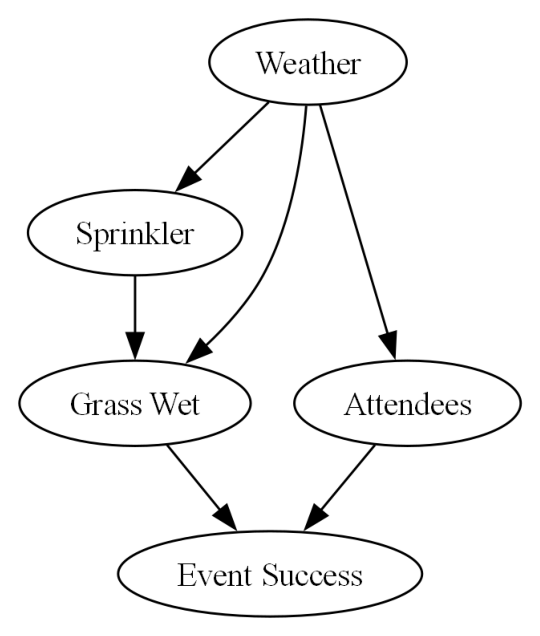

In [2]:
# Create a new Bayesian network
model = DiscreteBayesianNetwork()

# Add nodes (variables)
model.add_nodes_from(['Weather', 'Sprinkler', 'Grass Wet', 'Event Success', 'Attendees'])

# Add edges (relationships)
model.add_edges_from([('Weather', 'Sprinkler'),
                      ('Weather', 'Grass Wet'),
                      ('Sprinkler', 'Grass Wet'),
                      ('Weather', 'Attendees'),
                      ('Grass Wet', 'Event Success'),
                      ('Attendees', 'Event Success')])

# Weather: Sunny, Rainy, Cloudy
cpd_weather = TabularCPD(variable='Weather', variable_card=3, 
                         values=[[0.7], [0.2], [0.1]],  # Probabilities for Sunny, Rainy, Cloudy
                         state_names={'Weather': ['Sunny', 'Rainy', 'Cloudy']})

# Sprinkler: Depends on Weather
cpd_sprinkler = TabularCPD(variable='Sprinkler', variable_card=2,
                           values=[[0.7, 0.1, 0.3],  # Sprinkler On
                                   [0.3, 0.9, 0.7]],  # Sprinkler Off
                           evidence=['Weather'], evidence_card=[3],
                           state_names={'Sprinkler': ['On', 'Off'], 'Weather': ['Sunny', 'Rainy', 'Cloudy']})

# Grass Wet: Depends on Weather and Sprinkler
cpd_grass_wet = TabularCPD(variable='Grass Wet', variable_card=2,
                           values=[[0.99, 0.10, 0.90, 0.70, 0.80, 0.30],  # Grass Wet
                                   [0.01, 0.90, 0.10, 0.30, 0.20, 0.70]],  # Grass Dry
                           evidence=['Sprinkler', 'Weather'], evidence_card=[2, 3],
                           state_names={'Grass Wet': ['Wet', 'Dry'], 'Sprinkler': ['On', 'Off'], 'Weather': ['Sunny', 'Rainy', 'Cloudy']})

# Attendees: Depends on Weather
cpd_attendees = TabularCPD(variable='Attendees', variable_card=3,
                           values=[[0.6, 0.3, 0.5],  # High Attendance
                                   [0.3, 0.5, 0.4],  # Medium Attendance
                                   [0.1, 0.2, 0.1]],  # Low Attendance
                           evidence=['Weather'], evidence_card=[3],
                           state_names={'Attendees': ['High', 'Medium', 'Low'], 'Weather': ['Sunny', 'Rainy', 'Cloudy']})

# Event Success: Depends on Grass Wet and Attendees
cpd_event_success = TabularCPD(variable='Event Success', variable_card=2,
                               values=[[0.90, 0.80, 0.70, 0.60, 0.40, 0.20],  # Success
                                       [0.10, 0.20, 0.30, 0.40, 0.60, 0.80]],  # Failure
                               evidence=['Grass Wet', 'Attendees'], evidence_card=[2, 3],
                               state_names={'Event Success': ['Success', 'Failure'], 
                                            'Grass Wet': ['Wet', 'Dry'],
                                            'Attendees': ['High', 'Medium', 'Low']})

# Step 3: Add the CPDs to the Bayesian Network
model.add_cpds(cpd_weather, cpd_sprinkler, cpd_grass_wet, cpd_attendees, cpd_event_success)

# Convert model into pygraphviz object and visualize
model_graphviz = model.to_graphviz()
model_graphviz.graph_attr.update(size="15,8!")
# Draw the graph to binary PNG data
png_data = model_graphviz.draw(format='png', prog='dot')



# Create an image from the binary data
img = Image.open(io.BytesIO(png_data))

# Display the image
plt.figure(figsize=(15, 8))
plt.imshow(img, aspect='equal')
plt.axis('off')  # Hide axes
plt.show()

In [3]:
# Help functions
def visualize_mn(markov_net, title="Markov Network"):
    # Use a specific layout (you can try different layouts if spring_layout causes issues)
    pos = nx.shell_layout(markov_net)  # Alternative layout

    # Visualize the graph
    plt.figure(figsize=(8, 6))  # Set the size of the plot
    nx.draw(markov_net, pos, with_labels=True, node_size=5000, node_color="skyblue", font_size=12, font_weight="bold", edge_color="black")
    # add title
    plt.title(title, fontsize=15, fontweight="bold")
    # Display the graph
    plt.show()

def visualize_factor_graph(f_graph, title='Factor Graph'):
    G = nx.Graph()
    variable_nodes = set([x for factor in f_graph.get_factors() for x in factor.scope()]) #f_graph.get_variable_nodes()
    factor_nodes = set(f_graph.nodes()) - variable_nodes
    G.add_nodes_from(variable_nodes, bipartite=0)  # Variable nodes
    G.add_nodes_from(factor_nodes, bipartite=1) 
    # Add edges to the graph
    G.add_edges_from(f_graph.edges())
    # Step 4: Plot the graph
    pos = nx.shell_layout(G)  # Layout for positioning the nodes
    plt.figure(figsize=(15, 8))

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, nodelist=variable_nodes, node_color='lightblue', node_size=2000, label='Variables')
    nx.draw_networkx_nodes(G, pos, nodelist=factor_nodes, node_color='lightgreen', node_shape='s', node_size=3000, label='Factors')

    # Draw edges
    nx.draw_networkx_edges(G, pos, edgelist=f_graph.edges())

    # Draw labels for nodes
    nx.draw_networkx_labels(G, pos, font_size=12, font_color='black')

    # Show plot
    plt.title(title, fontsize=15, fontweight='bold')
    plt.axis('off')  # Turn off the axes
    plt.show()

### Task1: Perform Variable Elimination using Sum-Product Algorithm Step by Step: Compute the probability that the event is successful given that the weather is Sunny and the sprinkler is Off.

\begin{align*}
P(Event\ Success = Success \mid Weather=Sunny, Sprinkler=Off)
\end{align*}

### Step 1: Transform the Bayesian network into a Markov network.

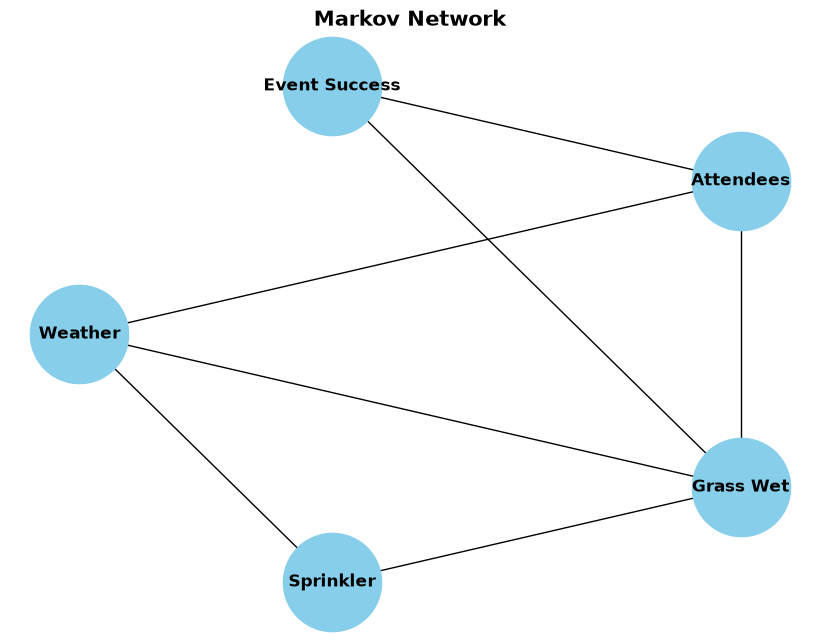

In [4]:
# Try to do it manually and verify it with the corresponding method of pgmpy
event_mn = model.to_markov_model()
visualize_mn(event_mn)

### Step 2: Transform the Markov network into a Factor Graph

A Factor Graph represents a Bayesian Network as a bipartite graph consisting of variable nodes and factor nodes. Each factor node represents a factor that involves one or more variables.

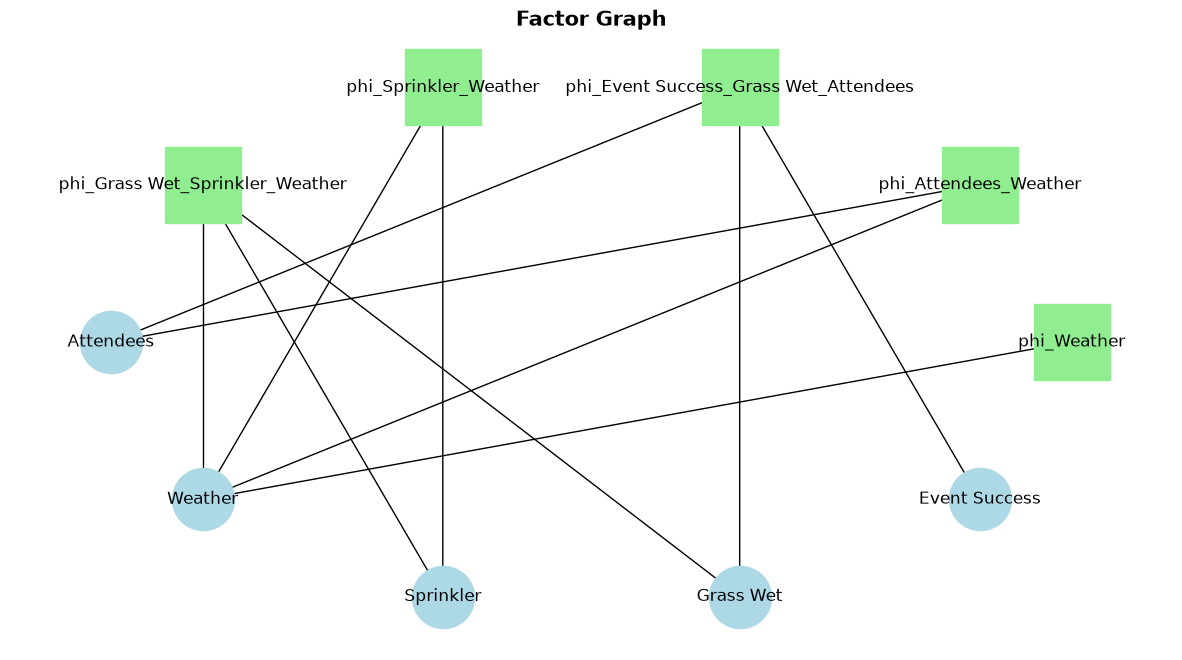

In [5]:
# Try to build a factor graph manually, then verify it with pgmpy.
event_factor_graph = event_mn.to_factor_graph()
visualize_factor_graph(event_factor_graph)

### Step 3: Write down the Factorization of the Gibbs Distribution

* W : Weather
* S : Sprinkler
* E : Event Success
* G : Grass Wet
* A : Attendees

$P(W, S, G, A, E) = \frac{1}{Z} \phi(W) \cdot \phi(S,W) \cdot \phi(G,S,W) \cdot \phi(W,A) \cdot \phi(E, G,A)$

$Z = 1$ because it originates from a Bayesian network.

### Step 4: Print All Factors.

In [6]:
for factor in event_mn.get_factors():
    print(factor)

+-----------------+----------------+
| Weather         |   phi(Weather) |
+=================+================+
| Weather(Sunny)  |         0.7000 |
+-----------------+----------------+
| Weather(Rainy)  |         0.2000 |
+-----------------+----------------+
| Weather(Cloudy) |         0.1000 |
+-----------------+----------------+
+----------------+-----------------+--------------------------+
| Sprinkler      | Weather         |   phi(Sprinkler,Weather) |
+================+=================+==========================+
| Sprinkler(On)  | Weather(Sunny)  |                   0.7000 |
+----------------+-----------------+--------------------------+
| Sprinkler(On)  | Weather(Rainy)  |                   0.1000 |
+----------------+-----------------+--------------------------+
| Sprinkler(On)  | Weather(Cloudy) |                   0.3000 |
+----------------+-----------------+--------------------------+
| Sprinkler(Off) | Weather(Sunny)  |                   0.3000 |
+----------------+---------

### Step 5: Identify the Query, Evidence Variables and Probability Query using Marginalization

* Query Variable: Event Success (E = Success)
* Evidence Variables: Weather (W=Sunny), Sprinkler (S=Off)
* Hidden Variables: Grass Wet (G), Attendees (A)

\begin{align*}
P(Event\ Success = Success \mid Weather=Sunny, Sprinkler=Off) = \sum_A \sum_G \phi(W)[W = Sunny] \cdot \phi(S,W)[S=Off,W=Sunny] \cdot \phi(G,S,W)[S=Off,W=Sunny]) \cdot \phi(W,A)[W=Sunny] \cdot \phi(E, G,A)
\end{align*}

### Step 6: Identify and Create the Factor $\psi$ involving only Evidence Variables.

You may compute the factor by hand, or create an instance of DiscreteFactor([factor_name], cardinality=[1],
                values=[value])

$\psi(W,S) = \phi(W) \cdot \phi(W, S)$

$\psi(W,S)[W=Sunny, S=off] = 0.7 * 0.3 = 0.21$

In [7]:
psi_W_S = DiscreteFactor(['W_S'], cardinality=[1],
                values=[0.7 * 0.3])
print(psi_W_S)

+--------+------------+
| W_S    |   phi(W_S) |
+========+============+
| W_S(0) |     0.2100 |
+--------+------------+


### Step 7: Reduce the Factors Involving Evidence by Keeping only the Entries in these Factors that Have the Observed Values. 

You may create a reduced factor by hand or use the method reduce([(variable_1, value_1), (variable_2, value_2),...], inplace=False) of the corresponding factor node.

In [8]:
# Use get_factors(node_name) of your Markov network model to show the involved factors.
factors = event_mn.get_factors()
phi_W = factors[0]
phi_S_W = factors[1]
phi_G_S_W = factors[2]
phi_A_W = factors[3]
phi_E_G_A = factors[4]

In [9]:
print(phi_G_S_W)

+----------------+----------------+-----------------+------------------------------------+
| Grass Wet      | Sprinkler      | Weather         |   phi(Grass Wet,Sprinkler,Weather) |
+================+================+=================+====================================+
| Grass Wet(Wet) | Sprinkler(On)  | Weather(Sunny)  |                             0.9900 |
+----------------+----------------+-----------------+------------------------------------+
| Grass Wet(Wet) | Sprinkler(On)  | Weather(Rainy)  |                             0.1000 |
+----------------+----------------+-----------------+------------------------------------+
| Grass Wet(Wet) | Sprinkler(On)  | Weather(Cloudy) |                             0.9000 |
+----------------+----------------+-----------------+------------------------------------+
| Grass Wet(Wet) | Sprinkler(Off) | Weather(Sunny)  |                             0.7000 |
+----------------+----------------+-----------------+------------------------------------+

In [10]:
reduced_phi_G_S_W = phi_G_S_W.reduce([('Weather','Sunny'),('Sprinkler','Off')],inplace=False)
print(reduced_phi_G_S_W)

+----------------+------------------+
| Grass Wet      |   phi(Grass Wet) |
+================+==================+
| Grass Wet(Wet) |           0.7000 |
+----------------+------------------+
| Grass Wet(Dry) |           0.3000 |
+----------------+------------------+


In [11]:
reduced_phi_A_W = phi_A_W.reduce([('Weather','Sunny')],inplace=False)
print(reduced_phi_A_W)

+-------------------+------------------+
| Attendees         |   phi(Attendees) |
+===================+==================+
| Attendees(High)   |           0.6000 |
+-------------------+------------------+
| Attendees(Medium) |           0.3000 |
+-------------------+------------------+
| Attendees(Low)    |           0.1000 |
+-------------------+------------------+


### Step 8: Choose an Elimination Ordering.

G -> A

### Step 9: Identify the Factors Involving the first Variable in the Elimination Ordering and Compute their Product as a New Factor.

Write down the equation for $\Psi(G, E, A, S=Off, W=Sunny)$ 

$\Psi(G, E, A)[S=Off, W=Sunny] = \phi(G) [S=Off, W=Sunny]\cdot \phi(E, G, A)$

In [12]:
# Use * to multiply two factors
psi_G_E_A = reduced_phi_G_S_W * phi_E_G_A
print(psi_G_E_A)

+-------------------+------------------------+----------------+------------------------------------------+
| Attendees         | Event Success          | Grass Wet      |   phi(Attendees,Event Success,Grass Wet) |
+===================+========================+================+==========================================+
| Attendees(High)   | Event Success(Success) | Grass Wet(Wet) |                                   0.6300 |
+-------------------+------------------------+----------------+------------------------------------------+
| Attendees(High)   | Event Success(Success) | Grass Wet(Dry) |                                   0.1800 |
+-------------------+------------------------+----------------+------------------------------------------+
| Attendees(High)   | Event Success(Failure) | Grass Wet(Wet) |                                   0.0700 |
+-------------------+------------------------+----------------+------------------------------------------+
| Attendees(High)   | Event Success(F

Compare with the product of the original factors, the multiplication with reduced factors reduces the size of the resulting product.

In [13]:
phi_G_S_W_A_E = phi_G_S_W * phi_E_G_A
print(phi_G_S_W_A_E)

+-------------------+-----------------+----------------+----------------+------------------------+------------------------------------------------------------+
| Attendees         | Weather         | Sprinkler      | Grass Wet      | Event Success          |   phi(Attendees,Weather,Sprinkler,Grass Wet,Event Success) |
+===================+=================+================+================+========================+============================================================+
| Attendees(High)   | Weather(Sunny)  | Sprinkler(On)  | Grass Wet(Wet) | Event Success(Success) |                                                     0.8910 |
+-------------------+-----------------+----------------+----------------+------------------------+------------------------------------------------------------+
| Attendees(High)   | Weather(Sunny)  | Sprinkler(On)  | Grass Wet(Wet) | Event Success(Failure) |                                                     0.0990 |
+-------------------+-----------------+-

### Step 10: Sum out the First Variable in the New Factor.

You may use the method marginalize([variable_1, variable_2, ...]) of a factor object to sum out the variables provided in the argument.

$\tau_1(E,A) = \sum_G \Psi(G, E, A)[S=Off, W=Sunny]$

In [14]:
tau_E_A = psi_G_E_A.marginalize(['Grass Wet'], inplace=False) 
print(tau_E_A)

+-------------------+------------------------+--------------------------------+
| Attendees         | Event Success          |   phi(Attendees,Event Success) |
+===================+========================+================================+
| Attendees(High)   | Event Success(Success) |                         0.8100 |
+-------------------+------------------------+--------------------------------+
| Attendees(High)   | Event Success(Failure) |                         0.1900 |
+-------------------+------------------------+--------------------------------+
| Attendees(Medium) | Event Success(Success) |                         0.6800 |
+-------------------+------------------------+--------------------------------+
| Attendees(Medium) | Event Success(Failure) |                         0.3200 |
+-------------------+------------------------+--------------------------------+
| Attendees(Low)    | Event Success(Success) |                         0.5500 |
+-------------------+-------------------

### Step 11: Repeat Step 9 and Step 10 for the Remaning Variables.

$ \psi(A, E) = \phi(A,W)[W=Sunny] \cdot \tau_1(E,A) $

In [15]:
psi_A_E = reduced_phi_A_W * tau_E_A
print(psi_A_E)

+-------------------+------------------------+--------------------------------+
| Attendees         | Event Success          |   phi(Attendees,Event Success) |
+===================+========================+================================+
| Attendees(High)   | Event Success(Success) |                         0.4860 |
+-------------------+------------------------+--------------------------------+
| Attendees(High)   | Event Success(Failure) |                         0.1140 |
+-------------------+------------------------+--------------------------------+
| Attendees(Medium) | Event Success(Success) |                         0.2040 |
+-------------------+------------------------+--------------------------------+
| Attendees(Medium) | Event Success(Failure) |                         0.0960 |
+-------------------+------------------------+--------------------------------+
| Attendees(Low)    | Event Success(Success) |                         0.0550 |
+-------------------+-------------------

$ \psi(A, E) = \sum_A \psi(A.E)$

In [16]:
tau_E = psi_A_E.marginalize(['Attendees'], inplace=False)
print(tau_E)

+------------------------+----------------------+
| Event Success          |   phi(Event Success) |
+========================+======================+
| Event Success(Success) |               0.7450 |
+------------------------+----------------------+
| Event Success(Failure) |               0.2550 |
+------------------------+----------------------+


### Verify Your Results with VariableElimination Method of pgmpy.

In [17]:
inf_ve = VariableElimination(model)

# Define the evidence
evidence_t1 = {
    'Weather': 'Sunny',
    'Sprinkler': 'Off'
}
query_t1 = inf_ve.query(
    variables=['Event Success'],
    evidence=evidence_t1,
    show_progress=False
)

print(query_t1)

+------------------------+----------------------+
| Event Success          |   phi(Event Success) |
+========================+======================+
| Event Success(Success) |               0.7450 |
+------------------------+----------------------+
| Event Success(Failure) |               0.2550 |
+------------------------+----------------------+


## Task 2: Answer Probability and MAP Queries
### Question 1: Compute the joint probability that the grass is wet and attendance is high given that the weather is Cloudy and the sprinkler is On.

\begin{align*}
P(G = Wet, A = High \mid W = Cloudy, S = On)
\end{align*}

In [18]:
# Define the inference object
inf_ve = VariableElimination(model)

# Define the evidence
evidence_q1 = {
    'Weather': 'Cloudy',
    'Sprinkler': 'On'
}

# Compute P(G = Wet, A = High | W = Cloudy, S = On)
# This can be computed as P(G = Wet | W = Cloudy, S = On) * P(A = High | W = Cloudy)

query_g_a = inf_ve.query(
    variables=['Grass Wet', 'Attendees'],
    evidence=evidence_q1,
    show_progress=False
)

print("P(G = Wet, A = High | W = Cloudy, S = On) = 0.45")
print(query_g_a)

P(G = Wet, A = High | W = Cloudy, S = On) = 0.45
+----------------+-------------------+----------------------------+
| Grass Wet      | Attendees         |   phi(Grass Wet,Attendees) |
+================+===================+============================+
| Grass Wet(Wet) | Attendees(High)   |                     0.4500 |
+----------------+-------------------+----------------------------+
| Grass Wet(Wet) | Attendees(Medium) |                     0.3600 |
+----------------+-------------------+----------------------------+
| Grass Wet(Wet) | Attendees(Low)    |                     0.0900 |
+----------------+-------------------+----------------------------+
| Grass Wet(Dry) | Attendees(High)   |                     0.0500 |
+----------------+-------------------+----------------------------+
| Grass Wet(Dry) | Attendees(Medium) |                     0.0400 |
+----------------+-------------------+----------------------------+
| Grass Wet(Dry) | Attendees(Low)    |                     0.0100 |

### Question 2: Most Likely Causes Given Observations [Evidential Reasoning]

What is the most likely combination of Weather and Sprinkler settings if the grass is Dry and attendance is Low?

\begin{align*}
argmax_{W, S} P(W, S \mid G = Dry, A = Low)
\end{align*}

In [19]:
# Define the evidence
evidence_q2a = {
    'Grass Wet': 'Dry',
    'Attendees': 'Low'
}

# Perform the MAP query for Weather and Sprinkler given the evidence
map_result_q2a = inf_ve.map_query(
    variables=['Weather', 'Sprinkler'],
    evidence=evidence_q2a,
    show_progress=False
)

print("\nMost likely Weather and Sprinkler settings given Grass Wet = Dry and Attendees = Low")
print(f"Most Probable Weather and Sprinkler: {map_result_q2a}")


Most likely Weather and Sprinkler settings given Grass Wet = Dry and Attendees = Low
Most Probable Weather and Sprinkler: {'Sprinkler': 'Off', 'Weather': 'Rainy'}


The most probable combination is Weather = Rainy and Sprinkler = Off. 

### Question 3: Investigate the probability of Sprinkler, given that the event fails 

\begin{align*}
P(S \mid E = Failure)
\end{align*}

In [20]:
# Define the evidence
evidence_q2b = {
    'Event Success': 'Failure'
}

# Perform the query for Sprinkler being Off given the evidence
query_result_q3 = inf_ve.query(
    variables=['Sprinkler'],
    evidence=evidence_q2b,
    show_progress=False
)

# Extract probabilities
prob_on = query_result_q3.values[0]    # On
prob_off = query_result_q3.values[1]   # Off

print(query_result_q3)

+----------------+------------------+
| Sprinkler      |   phi(Sprinkler) |
+================+==================+
| Sprinkler(On)  |           0.4130 |
+----------------+------------------+
| Sprinkler(Off) |           0.5870 |
+----------------+------------------+


### Question 4: Investigate the probability of Sprinkler given that the event fails, when it is raining. What conclusion would you draw?

\begin{align*}
 P(S \mid W = Rainy, E = Failure)
\end{align*}

In [21]:
# Define the evidence
evidence_q4 = {
    'Weather': 'Rainy',
    'Event Success': 'Failure'
}

# Perform the MAP query for Grass Wet and Attendees given the evidence
result_q4 = inf_ve.query(
    variables=['Sprinkler'],
    evidence=evidence_q4,
    show_progress=False
)

print(result_q4)

+----------------+------------------+
| Sprinkler      |   phi(Sprinkler) |
+================+==================+
| Sprinkler(On)  |           0.1832 |
+----------------+------------------+
| Sprinkler(Off) |           0.8168 |
+----------------+------------------+


The weather is rainy explains away the other possible factor sprinkler is on.